# Entrega 2 · Análisis exploratorio y modelos de referencia para el uso problemático de internet

**Viviana Fernández Payán · Universidad Icesi · MIAA 2026-2**

El objetivo es caracterizar la cohorte, la calidad de los datos y la disponibilidad de predictores y evaluar modelos de referencia para estimar la severidad. La variable objetivo es el índice ordinal de severidad `sii` (0: sin indicios según la escala, 1: leve, 2: moderado, 3: severo).

**Reproducción en Colab con Kaggle.** Genera un token en [Kaggle → API](https://www.kaggle.com/settings/api). En el panel **Secretos** de Colab (icono de llave), crea `KAGGLE_API_TOKEN` y activa **Acceso al cuaderno**. Con la misma cuenta de Kaggle, revisa el acceso a los datos y acepta las reglas del reto si Kaggle lo solicita. Al ejecutar el cuaderno, la primera celda reutiliza los CSV que ya estén disponibles y descarga desde Kaggle solo los que falten.

**Reproducción en Colab con archivos locales.** Descarga `train.csv` y `data_dictionary.csv` desde la [página de datos de la competencia](https://www.kaggle.com/competitions/child-mind-institute-problematic-internet-use/data). Extrae los CSV si vienen en un ZIP. Puedes subirlos a `/content/data` o `/content`, o esperar al selector de la primera celda. Conserva los nombres originales.

**Reproducción local.** Coloca los CSV en `data/` o define `PIU_DATA_DIR` con la ruta de la carpeta. Ejecuta el cuaderno con Python, pandas, NumPy y Matplotlib. La primera celda registra versiones y huellas SHA-256 de los insumos.

El cuaderno publica salidas agregadas y trabaja con los datos tabulares de entrenamiento. La actigrafía queda fuera de esta evaluación tabular. Los modelos y las pruebas iniciales se documentan en las secciones 6 a 10.

**Dependencias del modelado.** scikit-learn ≥ 1.2 y threadpoolctl. Google Colab suele incluir ambas bibliotecas. Para ejecutar localmente, instálalas junto con las dependencias del EDA.

In [ ]:
from hashlib import sha256
from pathlib import Path
import os
import sys

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

data_dir = Path(os.environ.get("PIU_DATA_DIR", "data")).expanduser()
filenames = ("train.csv", "data_dictionary.csv")
in_colab = "google.colab" in sys.modules or "COLAB_RELEASE_TAG" in os.environ
locations = [data_dir]
if in_colab:
    locations.extend([Path("/content/data"), Path("/content")])

def locate_csv(filename):
    return next((folder / filename for folder in locations
                 if (folder / filename).is_file()), None)

paths = {name: locate_csv(name) for name in filenames}
missing = [name for name, path in paths.items() if path is None]
if missing and in_colab:
    from google.colab import userdata

    try:
        kaggle_access = bool(userdata.get("KAGGLE_API_TOKEN").strip())
    except (userdata.SecretNotFoundError, userdata.NotebookAccessError, userdata.TimeoutException):
        kaggle_access = False

    if kaggle_access:
        try:
            import importlib.util
            import subprocess

            if importlib.util.find_spec("kagglehub") is None:
                subprocess.run(
                    [sys.executable, "-m", "pip", "install", "-q", "kagglehub"],
                    check=True,
                )
            import kagglehub

            competition = "child-mind-institute-problematic-internet-use"
            for name in missing:
                downloaded = Path(kagglehub.competition_download(competition, path=name))
                if not downloaded.is_file():
                    raise FileNotFoundError(f"Kaggle no entregó {name} como archivo.")
                paths[name] = downloaded
        except Exception as error:
            response = getattr(error, "response", None)
            status = getattr(response, "status_code", None)
            if status == 401:
                print("Kaggle no autenticó la solicitud (401). Revisa el token en Secretos.")
            elif status == 403:
                print("Kaggle denegó el acceso (403). Revisa el acceso al reto y sus reglas.")
            else:
                print("No se completó la descarga desde Kaggle.")
            print("Puedes continuar subiendo los CSV que falten.")

    missing = [name for name, path in paths.items() if path is None]

if missing and in_colab:
    from google.colab import files

    print("Selecciona los CSV que faltan: " + ", ".join(missing))
    data_dir.mkdir(parents=True, exist_ok=True)
    files.upload(target_dir=str(data_dir))
    for name in missing:
        paths[name] = locate_csv(name)
    missing = [name for name, path in paths.items() if path is None]

if missing:
    searched = ", ".join(dict.fromkeys(str(folder.resolve()) for folder in locations))
    raise FileNotFoundError(
        f"Faltan: {', '.join(missing)}. Rutas revisadas: {searched}. "
        "Extrae los CSV del ZIP si es necesario, conserva sus nombres originales "
        "y vuelve a ejecutar esta celda."
    )

train_path, dictionary_path = (paths[name] for name in filenames)
for path in (train_path, dictionary_path):
    print(f"{path.name} | SHA-256 {sha256(path.read_bytes()).hexdigest()}")

print(f"Python {sys.version.split()[0]} · pandas {pd.__version__} · "
      f"NumPy {np.__version__} · Matplotlib {matplotlib.__version__}")
train = pd.read_csv(train_path, dtype={"id": "string"})
dictionary = pd.read_csv(dictionary_path)

target = "sii"
age = "Basic_Demos-Age"
pciat = "PCIAT-PCIAT_Total"
classes = pd.Index([0, 1, 2, 3], name="sii")
labels = {0: "Sin indicios", 1: "Leve", 2: "Moderado", 3: "Severo"}

missing_fields = {"id", age, target, pciat} - set(train.columns)
if missing_fields or "Field" not in dictionary:
    raise ValueError(f"Faltan columnas clave en los insumos: {sorted(missing_fields)}")
if not train[target].dropna().isin(classes).all():
    raise ValueError("Se encontraron valores de sii fuera de las cuatro clases esperadas.")

print(f"Registros: {len(train):,} · variables: {train.shape[1]} · edades: "
      f"{train[age].min():.0f}–{train[age].max():.0f}")
print(f"ID faltante: {train['id'].isna().sum()} · "
      f"ID duplicado (ocurrencias adicionales): {train['id'].duplicated().sum()} · "
      f"filas duplicadas exactas (ocurrencias adicionales): {train.duplicated().sum()}")
print("Campos de train.csv que no figuran en el diccionario:",
      sorted(set(train.columns) - set(dictionary["Field"])))

train.csv | SHA-256 f3d32a58301631ba3897668fc167bcc6233b005e41c35c46a75586976d0737d7
data_dictionary.csv | SHA-256 b02dc663e565a6241f598b53d02692a685198852bd4b152f61a1f4a5231867a4
Python 3.12.14 · pandas 2.2.3 · NumPy 2.3.5 · Matplotlib 3.10.8
Registros: 3,960 · variables: 82 · edades: 5–22
ID faltante: 0 · ID duplicado (ocurrencias adicionales): 0 · filas duplicadas exactas (ocurrencias adicionales): 0
Campos de train.csv que no figuran en el diccionario: ['sii']


## 1. Población, disponibilidad de la etiqueta y desbalance

La cohorte principal abarca participantes de **5 a 17 años**, en línea con el alcance de la primera entrega. La distribución del conjunto completo y la del grupo de 18 a 22 años se presentan como contexto. Para las comparaciones por severidad se usan los registros con `sii` observado y se explicitan los denominadores. Los casos sin etiqueta permiten examinar cobertura.

In [ ]:
pediatric = train[train[age].between(5, 17)].copy()
adult = train[train[age].between(18, 22)].copy()
labeled = pediatric[pediatric[target].notna()].copy()

def target_summary(frame):
    count = int(frame[target].notna().sum())
    return {
        "registros": len(frame),
        "sii observado": count,
        "sii faltante": len(frame) - count,
        "% sii faltante": (1 - count / len(frame)) * 100 if len(frame) else np.nan,
    }

cohorts = {
    "HBN completo": train,
    "5 a 17 años": pediatric,
    "18 a 22 años": adult,
}
cohort_summary = pd.DataFrame({name: target_summary(frame) for name, frame in cohorts.items()}).T

frequency = pd.DataFrame({
    name: frame[target].value_counts().reindex(classes, fill_value=0)
    for name, frame in cohorts.items()
})
pediatric_pct = frequency["5 a 17 años"].div(len(labeled)).mul(100)
frequency["% entre menores con etiqueta"] = pediatric_pct
frequency.insert(0, "Nivel", classes.map(labels))

display(cohort_summary.round(2))
display(frequency.round(2))

age_bins = [4, 8, 12, 17]
age_groups = ["5–8", "9–12", "13–17"]
pediatric["Grupo de edad"] = pd.cut(pediatric[age], age_bins, labels=age_groups)
by_age = pediatric.groupby("Grupo de edad", observed=True)[target].agg(["size", "count"])
by_age.columns = ["registros", "sii observado"]
by_age["% sii faltante"] = (1 - by_age["sii observado"].div(by_age["registros"])) * 100
display(by_age.round(2))

,registros,sii observado,sii faltante,% sii faltante
HBN completo,3960.0,2736.0,1224.0,30.91
5 a 17 años,3798.0,2652.0,1146.0,30.17
18 a 22 años,162.0,84.0,78.0,48.15


,Nivel,HBN completo,5 a 17 años,18 a 22 años,% entre menores con etiqueta
sii,,,,,
0,Sin indicios,1594,1562,32,58.90
1,Leve,730,700,30,26.40
2,Moderado,378,360,18,13.57
3,Severo,34,30,4,1.13


,registros,sii observado,% sii faltante
Grupo de edad,,,
5–8,1407,1000,28.93
9–12,1512,1070,29.23
13–17,879,582,33.79


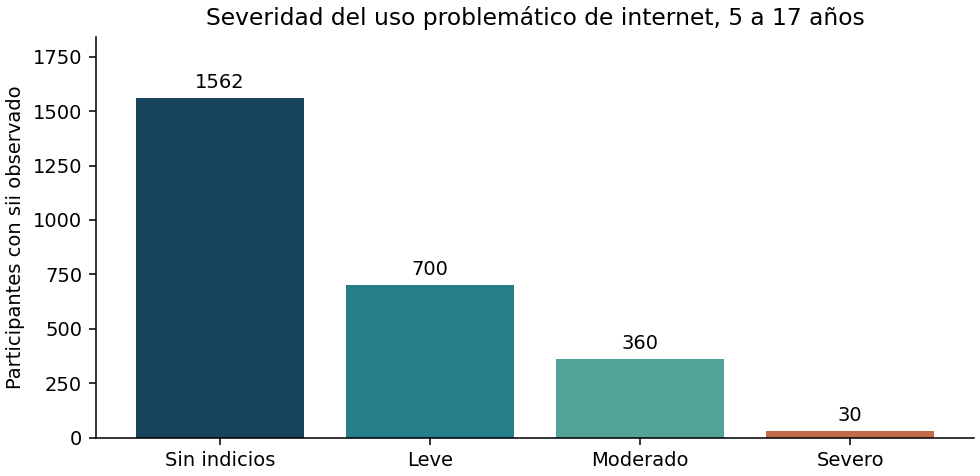

In [ ]:
fig, ax = plt.subplots(figsize=(7.0, 3.4), layout="constrained")
bars = ax.bar(frequency["Nivel"], frequency["5 a 17 años"],
              color=["#19445e", "#277d89", "#54a398", "#c36a48"])
ax.bar_label(bars, padding=3)
ax.set(title="Severidad del uso problemático de internet, 5 a 17 años",
       ylabel="Participantes con sii observado")
ax.margins(y=0.18)
ax.spines[["top", "right"]].set_visible(False)
plt.show()

## 2. Cobertura y control de calidad

La cobertura se calcula sobre todos los menores y sobre los menores con y sin etiqueta. Los puntajes PAQ-A y PAQ-C pertenecen a instrumentos diferentes. Sus faltantes se examinan por grupo de edad antes de decidir cómo usarlos.

Las señales de calidad se conservan como conteos de auditoría. Se señalan medidas físicas no positivas y registros con presión sistólica inferior a la diastólica. Son reglas de consistencia para revisión de unidades y captura.

In [ ]:
unlabeled = pediatric[pediatric[target].isna()].copy()
predictor_missing = pd.DataFrame({
    "% faltante en menores": pediatric[train.columns].isna().mean() * 100,
    "% faltante con sii": labeled.isna().mean() * 100,
    "% faltante sin sii": unlabeled[train.columns].isna().mean() * 100,
})
predictor_missing["Diferencia sin vs. con sii (pp)"] = (
    predictor_missing["% faltante sin sii"] - predictor_missing["% faltante con sii"]
)
predictor_fields = [
    field for field in train.columns
    if field not in {"id", target} and not field.startswith("PCIAT-")
]
display(predictor_missing.loc[predictor_fields].nlargest(12, "% faltante con sii").round(2))
display(predictor_missing.loc[predictor_fields].nlargest(8, "Diferencia sin vs. con sii (pp)").round(2))

paq_fields = ["PAQ_A-PAQ_A_Total", "PAQ_C-PAQ_C_Total"]
paq_coverage = pediatric.groupby("Grupo de edad", observed=True)[paq_fields].agg(
    lambda values: 100 * values.notna().mean()
)
print("Cobertura de PAQ por edad (% observado)")
display(paq_coverage.round(2))

physical = [
    "Physical-BMI", "Physical-Height", "Physical-Weight",
    "Physical-Waist_Circumference", "Physical-Systolic_BP",
    "Physical-Diastolic_BP", "Physical-HeartRate",
]
quality = pd.DataFrame({
    "observados": pediatric[physical].count(),
    "no positivos": pediatric[physical].le(0).sum(),
    "mínimo": pediatric[physical].min(),
    "máximo": pediatric[physical].max(),
})
display(quality.round(2))
pressures = pediatric[["Physical-Systolic_BP", "Physical-Diastolic_BP"]].dropna()
print("Registros con ambas presiones:", len(pressures))
print("Sistólica inferior a diastólica:",
      pressures["Physical-Systolic_BP"].lt(pressures["Physical-Diastolic_BP"]).sum())

Cobertura de PAQ por edad (% observado)
Registros con ambas presiones: 2844
Sistólica inferior a diastólica: 2


,% faltante en menores,% faltante con sii,% faltante sin sii,Diferencia sin vs. con sii (pp)
PAQ_A-Season,88.41,87.29,91.01,3.72
PAQ_A-PAQ_A_Total,88.41,87.29,91.01,3.72
Physical-Waist_Circumference,77.54,82.16,66.84,-15.32
Fitness_Endurance-Time_Mins,80.52,72.55,98.95,26.40
Fitness_Endurance-Time_Sec,80.52,72.55,98.95,26.40
Fitness_Endurance-Max_Stage,80.44,72.44,98.95,26.52
FGC-FGC_GSND_Zone,72.83,68.10,83.77,15.67
FGC-FGC_GSD_Zone,72.80,68.10,83.68,15.58
FGC-FGC_GSD,72.54,67.87,83.33,15.46
FGC-FGC_GSND,72.54,67.84,83.42,15.58


,% faltante en menores,% faltante con sii,% faltante sin sii,Diferencia sin vs. con sii (pp)
SDS-SDS_Total_T,32.70,6.64,93.02,86.38
SDS-SDS_Total_Raw,32.62,6.56,92.93,86.37
SDS-Season,32.39,6.56,92.15,85.59
CGAS-CGAS_Score,38.28,14.29,93.80,79.51
CGAS-Season,34.99,14.29,82.90,68.61
Physical-Weight,21.99,5.88,59.25,53.37
BIA-BIA_Activity_Level_num,49.50,33.63,86.21,52.58
BIA-BIA_BMC,49.50,33.63,86.21,52.58


,PAQ_A-PAQ_A_Total,PAQ_C-PAQ_C_Total
Grupo de edad,,
5–8,0.00,15.85
9–12,0.00,81.28
13–17,50.06,30.60


,observados,no positivos,mínimo,máximo
Physical-BMI,2911,7,0.0,59.13
Physical-Height,2916,0,33.0,77.00
Physical-Weight,2963,59,0.0,315.00
Physical-Waist_Circumference,853,0,18.0,50.00
Physical-Systolic_BP,2844,1,0.0,203.00
Physical-Diastolic_BP,2844,1,0.0,179.00
Physical-HeartRate,2857,0,27.0,138.00


## 3. Exploración por nivel de severidad

Se resumen edad e indicador de sueño con mediana y rango intercuartílico. El uso declarado de internet se presenta como proporción de la categoría más alta entre quienes tienen una respuesta válida. Cada resumen muestra cuántos datos lo sustentan. Las diferencias son descriptivas. La clase severa tiene pocos casos.

In [ ]:
sleep_field = "SDS-SDS_Total_T"
internet_field = "PreInt_EduHx-computerinternet_hoursday"
by_severity = labeled.groupby(target)

def summarize_numeric(field):
    grouped = by_severity[field]
    return pd.DataFrame({
        "n observado": grouped.count(),
        "Q1": grouped.quantile(0.25),
        "mediana": grouped.median(),
        "Q3": grouped.quantile(0.75),
    }).reindex(classes)

print("Edad (años)")
display(summarize_numeric(age).round(2))
print("Puntaje T de sueño")
display(summarize_numeric(sleep_field).round(2))

internet = labeled[labeled[internet_field].isin([0, 1, 2, 3])]
internet_counts = pd.crosstab(internet[target], internet[internet_field]).reindex(
    index=classes, columns=[0, 1, 2, 3], fill_value=0
)
internet_counts["n observado"] = internet_counts.sum(axis=1)
internet_counts["% categoría 3"] = (
    internet_counts[3].div(internet_counts["n observado"].replace(0, np.nan)) * 100
)
print("Uso declarado de internet por categoría. Categoría 3 = más de 3 h/día.")
display(internet_counts.round(2))
print("Valores observados fuera de los códigos 0–3:",
      (labeled[internet_field].notna() & ~labeled[internet_field].isin([0, 1, 2, 3])).sum())

Edad (años)
Puntaje T de sueño
Uso declarado de internet por categoría. Categoría 3 = más de 3 h/día.
Valores observados fuera de los códigos 0–3: 0


,n observado,Q1,mediana,Q3
sii,,,,
0,1562,7.0,8.5,10.00
1,700,9.0,11.0,13.00
2,360,10.0,12.0,14.00
3,30,13.0,14.0,15.75


,n observado,Q1,mediana,Q3
sii,,,,
0,1452,46.0,53.0,62.00
1,663,50.0,56.0,67.00
2,334,53.0,62.0,71.75
3,27,61.0,68.0,76.00


PreInt_EduHx-computerinternet_hoursday,0,1,2,3,n observado,% categoría 3
sii,,,,,,
0,933,156,358,67,1514,4.43
1,248,120,246,74,688,10.76
2,77,53,141,75,346,21.68
3,5,2,11,12,30,40.00


## 4. Fuga de información y matriz de variables

El contraste con los [cortes de puntuación del PCIAT](https://cmch.tv/wp-content/uploads/Scoring-Overview.pdf) comprueba la relación entre el puntaje total y `sii`. Para el modelado excluiré el bloque PCIAT completo (sus ítems, el total y su columna de temporada), el identificador y la etiqueta. Las columnas de temporada de otros instrumentos quedan en revisión por sus posibles relaciones con el proceso de recolección y la disponibilidad de mediciones.

Una primera configuración incluirá datos demográficos y medidas físicas o de aptitud, previa revisión de calidad y cobertura. Una segunda explorará el aporte adicional de sueño y uso declarado de internet. Los grupos son propuestas para la etapa de modelado y se comprobará la disponibilidad de los predictores en el momento de uso previsto.

In [ ]:
check = train[[target, pciat]].dropna()
reconstructed = pd.cut(
    check[pciat], [-np.inf, 30, 49, 79, 100], labels=classes
)
print("Registros con sii y PCIAT total:", len(check))
print("Discordancias entre sii y la categoría derivada de los cortes 30, 49 y 79:",
      reconstructed.astype(float).ne(check[target]).sum())
print("PCIAT total fuera del intervalo 0–100:", (~check[pciat].between(0, 100)).sum())
print("Registros con sii observado y PCIAT faltante:",
      (train[target].notna() & train[pciat].isna()).sum())

fields = pd.DataFrame({"Variable": train.columns})
meta = dictionary.set_index("Field")[["Instrument", "Description"]]
inventory = fields.join(meta, on="Variable").rename(
    columns={"Instrument": "Instrumento", "Description": "Descripción (fuente)"}
).set_index("Variable")
inventory.loc[target, ["Instrumento", "Descripción (fuente)"]] = [
    "Desenlace", "Índice ordinal de severidad",
]
inventory = inventory.join(predictor_missing[["% faltante en menores", "% faltante con sii"]])

def proposed_use(field):
    if field == target:
        return "Desenlace"
    if field == "id":
        return "Identificador"
    if field.startswith("PCIAT-"):
        return "Excluir (bloque del desenlace)"
    if field.endswith("-Season") or field.endswith("_Season"):
        return "Revisar (temporada)"
    if field in (internet_field, sleep_field, "SDS-SDS_Total_Raw"):
        return "Configuración ampliada (sueño o internet)"
    if field.startswith(("Basic_Demos-", "Physical-", "FGC-", "Fitness_Endurance-")):
        return "Configuración inicial (candidata)"
    return "Revisar (cobertura y pertinencia)"

inventory["Uso propuesto"] = inventory.index.map(proposed_use)
print("Matriz de campos y uso propuesto")
with pd.option_context("display.max_rows", None, "display.max_colwidth", 55):
    display(inventory.reset_index().round(2))

Registros con sii y PCIAT total: 2736
Discordancias entre sii y la categoría derivada de los cortes 30, 49 y 79: 0
PCIAT total fuera del intervalo 0–100: 0
Registros con sii observado y PCIAT faltante: 0
Matriz de campos y uso propuesto


,Variable,Instrumento,Descripción (fuente),% faltante en menores,% faltante con sii,Uso propuesto
0,id,Identifier,Participant's ID,0.00,0.00,Identificador
1,Basic_Demos-Enroll_Season,Demographics,Season of enrollment,0.00,0.00,Revisar (temporada)
2,Basic_Demos-Age,Demographics,Age of participant,0.00,0.00,Configuración inicial (candidata)
3,Basic_Demos-Sex,Demographics,Sex of participant,0.00,0.00,Configuración inicial (candidata)
4,CGAS-Season,Children's Global Assessment Scale,Season of participation,34.99,14.29,Revisar (temporada)
5,CGAS-CGAS_Score,Children's Global Assessment Scale,Children's Global Assessment Scale Score,38.28,14.29,Revisar (cobertura y pertinencia)
6,Physical-Season,Physical Measures,Season of participation,16.14,5.09,Revisar (temporada)
7,Physical-BMI,Physical Measures,Body Mass Index (kg/m^2),23.35,7.50,Configuración inicial (candidata)
8,Physical-Height,Physical Measures,Height (in),23.22,7.39,Configuración inicial (candidata)
9,Physical-Weight,Physical Measures,Weight (lbs),21.99,5.88,Configuración inicial (candidata)


## 5. Hallazgos y decisiones para la segunda entrega

- La cohorte de 5 a 17 años reúne **3.798 participantes**. **2.652** tienen `sii` observado y **1.146** carecen de etiqueta (30,2 %). La cobertura por instrumento merece revisión antes de tratar los faltantes como aleatorios.
- En la cohorte etiquetada hay **30 casos severos** (1,1 %). La comparación de modelos deberá reportar desempeño por categoría junto con QWK.
- La auditoría muestra cobertura desigual entre instrumentos y valores físicos que requieren revisión. El inventario documenta los campos iniciales, los candidatos de sueño e internet y las exclusiones por fuga de información.
- Los hallazgos describen una muestra del HBN. Las asociaciones exploradas se interpretan considerando la edad, los faltantes y la baja frecuencia del nivel severo.

Los conteos y tablas precedentes se calcularon con los CSV de entrenamiento identificados en la primera celda. Si se cambian los insumos, se deben actualizar también estos hallazgos.

## 6. Selección de variables e hipótesis

Para los experimentos uso los mismos **2.652 participantes de 5 a 17 años con `sii` observado**. La población completa del HBN se caracteriza en el EDA. Los 1.146 menores sin etiqueta permiten examinar diferencias de cobertura. La cohorte se mantiene fija al comparar bloques, incluso cuando faltan predictores.

| Bloque | Predictores | Justificación |
|---|---|---|
| A · Demográfico | Edad y sexo registrado | Referencia simple para medir cuánto agrega el resto de la información. |
| B · Físico | A + IMC, frecuencia cardiaca, presión arterial sistólica y diastólica | Mediciones con cobertura suficiente para la prueba inicial y unidades definidas en el diccionario. |
| B + sueño | B + puntaje T de sueño (SDS) | Prueba el aporte del sueño sin el predictor de internet. |
| B + internet | B + categoría de uso declarado de internet | Prueba el aporte del uso declarado sin el predictor de sueño. Es una medida separada del PCIAT. |
| C · Ampliado | B + sueño + internet | Evalúa el aporte conjunto de ambos predictores. |

Priorizo medidas físicas con cobertura superior al 90 % en la cohorte etiquetada antes de los controles de consistencia. La cintura y la prueba de resistencia presentan muchos faltantes. PAQ-A y PAQ-C tienen coberturas diferentes según la edad. Para la prueba inicial, dejo fuera estas variables, las temporadas de medición, la actigrafía, el identificador y todo el bloque PCIAT. El puntaje T de sueño evita incorporar simultáneamente su puntaje bruto. La categoría de uso declarado de internet se codifica como categórica porque sus niveles son intervalos, incluidos extremos abiertos.

| Hipótesis | Prueba inicial | Indicador |
|---|---|---|
| H1. Los modelos con predictores aportan capacidad discriminante sobre la regla de clase mayoritaria. | Comparar logística y bosque aleatorio en A, B y C frente a la línea base. Contrastar B con A para estimar el aporte incremental físico. | QWK, F1 macro y sensibilidad por clase. |
| H2. Sueño e internet aportan información incremental sobre B. | Comparar C, B + sueño y B + internet con B, dentro de cada modelo y sobre los mismos pliegues. Contrastar C con B + internet para examinar el aporte de sueño cuando ya se conoce el uso declarado. | Diferencia pareada de QWK por pliegue y consistencia del signo. |
| H3. Ponderar las clases mejora la identificación de casos severos. | Comparar C con y sin pesos balanceados para cada modelo. | Sensibilidad y precisión de la clase 3, F1 macro y QWK. |

Para estimar el aporte de cada grupo de predictores, comparé los bloques sobre los mismos pliegues de validación. En cada pliegue calculé la diferencia de QWK entre configuraciones del mismo modelo.

## 7. Modelos de referencia y protocolo

Comparo una **línea base de clase mayoritaria**, **regresión logística multinomial regularizada L2** y **bosque aleatorio**. Evalúo todos con las mismas 15 particiones de validación cruzada estratificada (5 pliegues × 3 repeticiones, semilla 42). Los hiperparámetros son fijos. Cada repetición genera una predicción fuera de muestra por participante y configuración.

La imputación por mediana o moda, la codificación categórica y el escalado de la logística se ajustan dentro del entrenamiento de cada pliegue. Antes de imputar se tratan como faltantes las mediciones físicas no positivas, los pares de presión inconsistentes y los códigos fuera de catálogo. La evaluación usa las cuatro clases con QWK como criterio principal, además de F1 macro, exactitud, error absoluto ordinal y sensibilidad y precisión de la clase severa. Ante ausencia de predicciones severas, su precisión se registra en 0 junto con el recuento de predicciones. La dispersión entre pliegues es descriptiva porque las particiones comparten observaciones.

[Validación estratificada repetida](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.RepeatedStratifiedKFold.html) · [Prevención de fuga de datos](https://scikit-learn.org/stable/common_pitfalls.html#data-leakage).

In [ ]:
import sklearn
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, cohen_kappa_score, confusion_matrix,
                             f1_score, mean_absolute_error, precision_score, recall_score)
from sklearn.model_selection import RepeatedStratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from threadpoolctl import threadpool_limits

seed, n_folds, n_repeats = 42, 5, 3
demographics = [age, "Basic_Demos-Sex"]
physical_fields = ["Physical-BMI", "Physical-HeartRate",
                   "Physical-Systolic_BP", "Physical-Diastolic_BP"]
blocks = {
    "A": demographics,
    "B": demographics + physical_fields,
    "B + sueño": demographics + physical_fields + [sleep_field],
    "B + internet": demographics + physical_fields + [internet_field],
    "C": demographics + physical_fields + [sleep_field, internet_field],
}
categorical = {"Basic_Demos-Sex": [0, 1], internet_field: [0, 1, 2, 3]}
features = labeled[blocks["C"]].copy()
assert labeled["id"].notna().all() and labeled["id"].is_unique
assert not any(name in {"id", target} or name.startswith("PCIAT-") for name in features)
features[physical_fields] = features[physical_fields].where(features[physical_fields].gt(0))
pressure_fields = ["Physical-Systolic_BP", "Physical-Diastolic_BP"]
inconsistent_bp = features[pressure_fields[0]].lt(features[pressure_fields[1]])
features.loc[inconsistent_bp, pressure_fields] = np.nan
for name, valid_codes in categorical.items():
    features[name] = features[name].where(features[name].isin(valid_codes))
features = features.reset_index(drop=True)
y = labeled[target].astype(int).to_numpy()
if pd.Series(y).value_counts().min() < n_folds:
    raise ValueError("Cada clase debe tener al menos cinco registros para el esquema de validación.")
splits = list(RepeatedStratifiedKFold(n_splits=n_folds, n_repeats=n_repeats,
                                     random_state=seed).split(features, y))
print(f"scikit-learn {sklearn.__version__} · {len(y):,} participantes · {len(splits)} pliegues")
display(features.isna().mul(100).mean().rename("% faltante tras controles").round(2).to_frame())

models = {
    "Logística": LogisticRegression(C=1.0, solver="lbfgs", max_iter=2000),
    "Bosque aleatorio": RandomForestClassifier(
        n_estimators=120, min_samples_leaf=5, max_features="sqrt", random_state=seed, n_jobs=1
    ),
}

def make_pipeline(estimator, fields):
    numeric = [name for name in fields if name not in categorical]
    cat = [name for name in fields if name in categorical]
    numeric_steps = [("imputar", SimpleImputer(strategy="median"))]
    if isinstance(estimator, LogisticRegression):
        numeric_steps.append(("escalar", StandardScaler()))
    transformer = ColumnTransformer([
        ("num", Pipeline(numeric_steps), numeric),
        ("cat", Pipeline([
            ("imputar", SimpleImputer(strategy="most_frequent")),
            ("codificar", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
        ]), cat),
    ])
    return Pipeline([("preparar", transformer), ("modelo", estimator)])

scikit-learn 1.8.0 · 2,652 participantes · 15 pliegues


,% faltante tras controles
Basic_Demos-Age,0.00
Basic_Demos-Sex,0.00
Physical-BMI,7.77
Physical-HeartRate,9.01
Physical-Systolic_BP,9.39
Physical-Diastolic_BP,9.39
SDS-SDS_Total_T,6.64
PreInt_EduHx-computerinternet_hoursday,2.79


In [ ]:
strategies = {("Mayoritaria", "A", "Sin ponderar"): DummyClassifier(strategy="most_frequent")}
for name, model in models.items():
    for block, columns in blocks.items():
        strategies[(name, block, "Sin ponderar")] = make_pipeline(clone(model), columns)
    balanced = clone(model).set_params(class_weight="balanced")
    strategies[(name, "C", "Balanceado")] = make_pipeline(balanced, blocks["C"])

def measure(actual, predicted):
    return {
        "QWK": cohen_kappa_score(actual, predicted, labels=list(classes), weights="quadratic"),
        "F1 macro": f1_score(actual, predicted, labels=list(classes),
                             average="macro", zero_division=0),
        "Exactitud": accuracy_score(actual, predicted),
        "MAE ordinal": mean_absolute_error(actual, predicted),
        "Sensibilidad 3": recall_score(actual, predicted, labels=[3],
                                      average="macro", zero_division=0),
        "Precisión 3": precision_score(actual, predicted, labels=[3],
                                      average="macro", zero_division=0),
        "Predichos 3": int((predicted == 3).sum()),
    }

fold_rows = []
repeat_rows = []
oof_by_strategy = {}
with threadpool_limits(limits=1):
    for key, strategy in strategies.items():
        model_name, block, weighting = key
        x = features[blocks[block]]
        oof = np.full((n_repeats, len(y)), -1, dtype=int)
        for number, (fit_rows, eval_rows) in enumerate(splits):
            repetition, fold = divmod(number, n_folds)
            model = clone(strategy).fit(x.iloc[fit_rows], y[fit_rows])
            pred = model.predict(x.iloc[eval_rows]).astype(int)
            assert (oof[repetition, eval_rows] == -1).all()
            oof[repetition, eval_rows] = pred
            fold_rows.append([*key, repetition + 1, fold + 1, *measure(y[eval_rows], pred).values()])
        assert np.isin(oof, classes).all()
        oof_by_strategy[key] = oof
        for repetition, pred in enumerate(oof, start=1):
            repeat_rows.append([*key, repetition, *measure(y, pred).values()])

identity = ["Modelo", "Bloque", "Pesos"]
metric_names = list(measure(y, y))
fold_metrics = pd.DataFrame(fold_rows, columns=identity + ["Repetición", "Pliegue"] + metric_names)
rep_metrics = pd.DataFrame(repeat_rows, columns=identity + ["Repetición"] + metric_names)

cv_groups = fold_metrics.groupby(identity, sort=False)
summary_models = cv_groups[metric_names[:-1]].mean()
summary_models.insert(1, "DE QWK", cv_groups["QWK"].std())
summary_models["Predichos 3 / cohorte"] = (
    rep_metrics.groupby(identity, sort=False)["Predichos 3"].mean()
)
summary_models = summary_models.sort_values("QWK", ascending=False)
print("Media por pliegue. Predichos 3 corresponde a la media por repetición OOF.")
display(summary_models.round(3))

Media por pliegue. Predichos 3 corresponde a la media por repetición OOF.


QWK  ...  Predichos 3 / cohorte
Modelo           Bloque       Pesos                ...                       
Bosque aleatorio C            Balanceado    0.407  ...                 33.000
Logística        C            Balanceado    0.396  ...                304.667
                              Sin ponderar  0.346  ...                  4.667
Bosque aleatorio C            Sin ponderar  0.318  ...                  0.000
Logística        B + internet Sin ponderar  0.282  ...                  3.000
                 B + sueño    Sin ponderar  0.270  ...                  4.333
Bosque aleatorio B + sueño    Sin ponderar  0.260  ...                  0.000
                 B + internet Sin ponderar  0.236  ...                  0.000
Logística        B            Sin ponderar  0.200  ...                  2.667
Bosque aleatorio A            Sin ponderar  0.198  ...                  0.000
Logística        A            Sin ponderar  0.195  ...                  0.000
Bosque aleatorio B            Sin ponderar  0.165  ...                  0.000
Mayoritaria      A            Sin ponderar  0.000  ...                  0.000

[13 rows x 8 columns]

## 8. Resultados pareados y análisis de errores

Las diferencias de QWK se calculan por pliegue usando los mismos registros de validación en ambos lados. Se presenta la dispersión observada y el número de pliegues con mejora. La matriz de confusión usa la primera repetición completa, con una predicción fuera de muestra por participante. Para cada familia se muestra C con y sin ponderación junto a la línea base.

In [ ]:
paired_rows = []
for name in models:
    scores = fold_metrics[(fold_metrics["Modelo"] == name) &
                          (fold_metrics["Pesos"] == "Sin ponderar")].pivot(
        index=["Repetición", "Pliegue"], columns="Bloque", values="QWK")
    for newer, older in (("B", "A"), ("B + sueño", "B"), ("B + internet", "B"),
                         ("C", "B"), ("C", "B + internet")):
        delta = scores[newer] - scores[older]
        paired_rows.append([name, f"{newer} vs. {older}", delta.mean(), delta.std(),
                            int(delta.gt(0).sum()), len(delta)])
paired = pd.DataFrame(paired_rows, columns=["Modelo", "Comparación", "Δ QWK medio",
                                           "DE del Δ", "Pliegues con mejora", "Pliegues"])
display(paired.round(3))

matrices = {
    key: confusion_matrix(y, predictions[0], labels=list(classes))
    for key, predictions in oof_by_strategy.items()
}
focus = [("Mayoritaria", "A", "Sin ponderar")] + [
    (name, "C", weights) for name in models for weights in ("Sin ponderar", "Balanceado")
]
for key in focus:
    counts_by_class = matrices[key]
    np.testing.assert_array_equal(counts_by_class.sum(axis=1), np.bincount(y, minlength=4))
    print(" · ".join(key), "| repetición 1 | filas: observado; columnas: predicho")
    display(pd.DataFrame(counts_by_class, index=classes, columns=list(classes)))

class_rows = []
for key in focus:
    pred = oof_by_strategy[key]
    recalls = np.array([recall_score(y, row, labels=list(classes), average=None,
                                      zero_division=0) for row in pred])
    class_rows.append([*key, *recalls.mean(axis=0)])
class_recall = pd.DataFrame(class_rows, columns=identity + [f"Sensibilidad {c}" for c in classes])
print("Sensibilidad por categoría, media de las tres repeticiones OOF")
display(class_recall.round(3))

Mayoritaria · A · Sin ponderar | repetición 1 | filas: observado; columnas: predicho
Logística · C · Sin ponderar | repetición 1 | filas: observado; columnas: predicho
Logística · C · Balanceado | repetición 1 | filas: observado; columnas: predicho
Bosque aleatorio · C · Sin ponderar | repetición 1 | filas: observado; columnas: predicho
Bosque aleatorio · C · Balanceado | repetición 1 | filas: observado; columnas: predicho
Sensibilidad por categoría, media de las tres repeticiones OOF


,Modelo,Comparación,Δ QWK medio,DE del Δ,Pliegues con mejora,Pliegues
0,Logística,B vs. A,0.005,0.026,10,15
1,Logística,B + sueño vs. B,0.071,0.016,15,15
2,Logística,B + internet vs. B,0.082,0.018,15,15
3,Logística,C vs. B,0.146,0.027,15,15
4,Logística,C vs. B + internet,0.064,0.027,15,15
5,Bosque aleatorio,B vs. A,-0.033,0.047,4,15
6,Bosque aleatorio,B + sueño vs. B,0.096,0.038,15,15
7,Bosque aleatorio,B + internet vs. B,0.071,0.032,15,15
8,Bosque aleatorio,C vs. B,0.153,0.041,15,15
9,Bosque aleatorio,C vs. B + internet,0.082,0.050,15,15


,0,1,2,3
sii,,,,
0,1562,0,0,0
1,700,0,0,0
2,360,0,0,0
3,30,0,0,0


,0,1,2,3
sii,,,,
0,1398,121,42,1
1,494,156,48,2
2,173,117,69,1
3,7,7,15,1


,0,1,2,3
sii,,,,
0,1062,269,145,86
1,243,198,165,94
2,57,91,111,101
3,1,1,11,17


,0,1,2,3
sii,,,,
0,1382,146,34,0
1,496,144,60,0
2,190,114,56,0
3,5,12,13,0


,0,1,2,3
sii,,,,
0,1114,287,155,6
1,288,236,163,13
2,80,129,138,13
3,1,3,25,1


,Modelo,Bloque,Pesos,Sensibilidad 0,Sensibilidad 1,Sensibilidad 2,Sensibilidad 3
0,Mayoritaria,A,Sin ponderar,1.000,0.000,0.000,0.000
1,Logística,C,Sin ponderar,0.898,0.221,0.192,0.033
2,Logística,C,Balanceado,0.681,0.280,0.313,0.622
3,Bosque aleatorio,C,Sin ponderar,0.882,0.207,0.163,0.000
4,Bosque aleatorio,C,Balanceado,0.708,0.347,0.377,0.089


## 9. Evidencia reproducible

Los resultados tabulares se pueden exportar de forma opcional. La exportación incluye las métricas por pliegue, los resultados por repetición, las diferencias pareadas, las matrices de confusión agregadas y el inventario de variables. Las matrices y tablas permiten revisar los experimentos sin publicar identificadores ni predicciones individuales.

In [ ]:
export_dir = os.environ.get("PIU_RESULTS_DIR")
if export_dir:
    results_path = Path(export_dir)
    results_path.mkdir(parents=True, exist_ok=True)
    tables = {
        "resultado_modelos": summary_models.reset_index(),
        "metricas_por_pliegue": fold_metrics,
        "metricas_por_repeticion": rep_metrics,
        "diferencias_qwk": paired,
        "sensibilidad_por_clase": class_recall,
        "inventario_variables": inventory.reset_index(),
    }
    for name, table in tables.items():
        table.to_csv(results_path / f"{name}.csv", index=False)
    matrix_rows = [
        [*key, int(actual), int(predicted), int(matrix[actual, predicted])]
        for key, matrix in matrices.items() for actual in classes for predicted in classes
    ]
    pd.DataFrame(matrix_rows, columns=identity + ["Observado", "Predicho", "n"]).to_csv(
        results_path / "matrices_primera_repeticion.csv", index=False
    )
    print("Tablas agregadas guardadas en", results_path)

## 10. Interpretación para la segunda entrega

La regla mayoritaria obtuvo una exactitud de **58,9 %** y QWK de **0,000**. El QWK medio más alto de esta comparación fue **0,407** con **Bosque aleatorio · C · Balanceado**. El mayor QWK supera la meta exploratoria de 0,35 en esta evaluación interna.

| Modelo y bloque | QWK medio ± DE | F1 macro | Sensibilidad severa | Precisión severa |
|---|---:|---:|---:|---:|
| Mayoritaria · A · Sin ponderar | 0,000 ± 0,000 | 0,185 | 0,0 % | 0,0 % |
| Logística · C · Sin ponderar | 0,346 ± 0,038 | 0,340 | 3,3 % | 12,2 % |
| Logística · C · Balanceado | 0,396 ± 0,029 | 0,358 | 62,2 % | 6,1 % |
| Bosque aleatorio · C · Sin ponderar | 0,318 ± 0,038 | 0,310 | 0,0 % | 0,0 % |
| Bosque aleatorio · C · Balanceado | 0,407 ± 0,041 | 0,372 | 8,9 % | 7,8 % |

- **Logística.** Δ QWK de B respecto de A = 0,005. Frente a B, el delta medio fue 0,071 con sueño, 0,082 con internet y 0,146 con ambos (15/15 pliegues con mejora para C). Añadir sueño cuando ya estaba internet produjo un delta de 0,064. Con ponderación, la sensibilidad severa pasó de 3,3 % a 62,2 % y la precisión quedó en 6,1 %.
- **Bosque aleatorio.** Δ QWK de B respecto de A = -0,033. Frente a B, el delta medio fue 0,096 con sueño, 0,071 con internet y 0,153 con ambos (15/15 pliegues con mejora para C). Añadir sueño cuando ya estaba internet produjo un delta de 0,082. Con ponderación, la sensibilidad severa pasó de 0,0 % a 8,9 % y la precisión quedó en 7,8 %.

Las mejoras corresponden a una comparación exploratoria sobre el mismo conjunto con el que se examinaron cobertura y asociaciones. La dispersión por pliegue, la cantidad de predicciones severas y las matrices de confusión son necesarias para interpretar los cambios. El grupo severo tiene solo 30 participantes y la ponderación puede aumentar los falsos positivos. El uso declarado de internet se interpreta como predictor concurrente. Una mejora del QWK al incorporarlo no demuestra causalidad ni desempeño en detección futura. Los datos del HBN provienen de una muestra clínica y los resultados requieren confirmación con otras particiones o con una muestra externa.

### Correspondencia con la rúbrica

| Componente | Evidencia en este cuaderno |
|---|---|
| EDA y selección de datos y variables (5 %) | Secciones 1–6. Cohorte, etiqueta, cobertura según edad, calidad de datos, revisión de fuga y justificación de bloques. |
| Modelos de referencia y experimentos (5 %) | Secciones 6–10. Hipótesis, línea base, modelos, protocolo, contrastes pareados y análisis de errores por clase. |